# EDA датасета EPITOME

Три оценки эмпатии в ответах Reddit. Уровень 0 означает отсутствие признака, 1 — слабое проявление, 2 — сильное.

## Импорты

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Первый взгляд на данные

Путь `upload/` можно убрать, если CSV лежат рядом с ноутбуком.

In [2]:
er = pd.read_csv("upload/emotional-reactions-reddit.csv", keep_default_na=False)
ip = pd.read_csv("upload/interpretations-reddit.csv", keep_default_na=False)
ex = pd.read_csv("upload/explorations-reddit.csv", keep_default_na=False)

er["признак"] = "Эмоциональная реакция"
ip["признак"] = "Понимание переживаний"
ex["признак"] = "Уточнение переживаний"

df = pd.concat([er, ip, ex], ignore_index=True)
key = ["sp_id", "rp_id"]
display(df.groupby("признак").size().rename("Строк"))

,Строк
признак,
Понимание переживаний,3084
Уточнение переживаний,3084
Эмоциональная реакция,3084


In [3]:
display(df.groupby("признак", sort=False).head(1))

,sp_id,rp_id,seeker_post,response_post,level,rationales,признак
0,65m92s,dgbdk7z,Help. Help me. I dunno what I'm doing anymore,"That's pretty vague, do you not know what you're doing in regards to a specific section of your life? Like school or work?",0,,Эмоциональная реакция
3084,65m92s,dgbdk7z,Help. Help me. I dunno what I'm doing anymore,"That's pretty vague, do you not know what you're doing in regards to a specific section of your life? Like school or work?",0,,Понимание переживаний
6168,65m92s,dgbdk7z,Help. Help me. I dunno what I'm doing anymore,"That's pretty vague, do you not know what you're doing in regards to a specific section of your life? Like school or work?",2,do you not know what you're doing in regards to a specific section of your life? Like school or work?|,Уточнение переживаний


In [4]:
display(df.replace(r"^\s*$", pd.NA, regex=True).isna().groupby(df["признак"]).sum().T)

признак,Понимание переживаний,Уточнение переживаний,Эмоциональная реакция
sp_id,0,0,0
rp_id,0,0,0
seeker_post,0,0,0
response_post,0,0,0
level,0,0,0
rationales,1634,2605,2039
признак,0,0,0


Пустые обоснования ожидаемы при уровне 0. Ниже проверим их отдельно по уровням.

## Начало анализа

In [5]:
counts = pd.crosstab(df["признак"], df["level"])
display(counts)

level,0,1,2
признак,,,
Понимание переживаний,1626,114,1344
Уточнение переживаний,2604,104,376
Эмоциональная реакция,2037,895,152


In [6]:
shares = counts.div(counts.sum(axis=1), axis=0).mul(100)
display(shares.round(2))

level,0,1,2
признак,,,
Понимание переживаний,52.72,3.70,43.58
Уточнение переживаний,84.44,3.37,12.19
Эмоциональная реакция,66.05,29.02,4.93


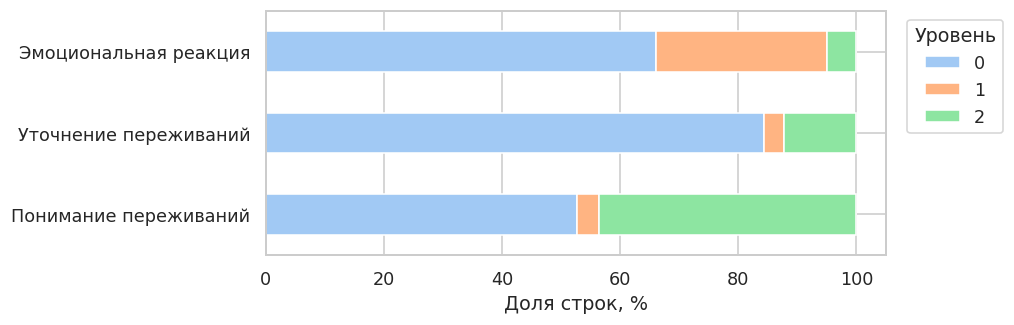

In [7]:
ax = shares.plot.barh(stacked=True, figsize=(9, 3), color=sns.color_palette("pastel", 3))
ax.set(xlabel="Доля строк, %", ylabel="")
ax.legend(title="Уровень", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Уровень 0 самый частый во всех трёх файлах. У эмоциональной реакции уровень 2 встречается только в 4,93% строк.

## Проверка качества данных

In [8]:
quality = []
for name, part in df.groupby("признак"):
    quality.append({
        "Признак": name,
        "Полные дубликаты": part.duplicated().sum(),
        "Уникальные пары": len(part.drop_duplicates(key)),
        "Повторные строки по ключу": part.duplicated(key).sum(),
        "Ключи с разными оценками": part.groupby(key)["level"].nunique().gt(1).sum(),
    })
display(pd.DataFrame(quality).set_index("Признак"))

,Полные дубликаты,Уникальные пары,Повторные строки по ключу,Ключи с разными оценками
Признак,,,,
Понимание переживаний,38,3023,61,10
Уточнение переживаний,56,3023,61,5
Эмоциональная реакция,33,3023,61,10


В каждом файле 3 084 строки и 3 023 уникальных ключа пары. Для сравнения разметок оставим только пары, ключ которых встречается ровно один раз в каждом файле. Распределения выше рассчитаны по всем строкам.

In [9]:
has_rationale = df["rationales"].str.strip().ne("")
display(pd.crosstab([df["признак"], df["level"]], has_rationale)
        .rename(columns={False: "Пусто", True: "Заполнено"}))

rationales                   Пусто  Заполнено
признак               level                  
Понимание переживаний 0       1626          0
                      1          0        114
                      2          8       1336
Уточнение переживаний 0       2604          0
                      1          1        103
                      2          0        376
Эмоциональная реакция 0       2037          0
                      1          2        893
                      2          0        152

## Корреляции признаков

In [10]:
levels = df.drop_duplicates(key + ["признак"], keep=False)
levels = levels.pivot(index=key, columns="признак", values="level").dropna()

texts = ["seeker_post", "response_post"]
er_text = er.set_index(key).loc[levels.index, texts]
ip_text = ip.set_index(key).loc[levels.index, texts]
ex_text = ex.set_index(key).loc[levels.index, texts]

er_text = er_text.replace(r"\s+", " ", regex=True).apply(lambda col: col.str.strip())
ip_text = ip_text.replace(r"\s+", " ", regex=True).apply(lambda col: col.str.strip())
ex_text = ex_text.replace(r"\s+", " ", regex=True).apply(lambda col: col.str.strip())

same_text = er_text.eq(ip_text).all(axis=1) & er_text.eq(ex_text).all(axis=1)
print("Пар с однозначным ключом:", len(levels))
print("Из них совпадает текст после нормализации пробелов:", same_text.sum())

Пар с однозначным ключом: 2963
Из них совпадает текст после нормализации пробелов: 2928


Из 2 963 однозначных пар у 35 текст различается даже после нормализации пробелов. Для корреляции используем остальные 2 928.

In [11]:
display(levels.loc[same_text].corr(method="spearman").round(3))

признак,Понимание переживаний,Уточнение переживаний,Эмоциональная реакция
признак,,,
Понимание переживаний,1.000,-0.222,-0.130
Уточнение переживаний,-0.222,1.000,-0.057
Эмоциональная реакция,-0.130,-0.057,1.000


## Длина текста и уровень эмпатии

In [12]:
df["Слов в посте"] = df["seeker_post"].str.split().str.len()
df["Слов в ответе"] = df["response_post"].str.split().str.len()
display(df.groupby(["признак", "level"])[["Слов в посте", "Слов в ответе"]].median())

Слов в посте  Слов в ответе
признак               level                             
Понимание переживаний 0              28.0           19.0
                      1              33.0           27.0
                      2              32.0           41.0
Уточнение переживаний 0              30.0           29.0
                      1              23.5           15.0
                      2              32.0           23.0
Эмоциональная реакция 0              30.0           25.0
                      1              29.0           36.0
                      2              30.0           29.0

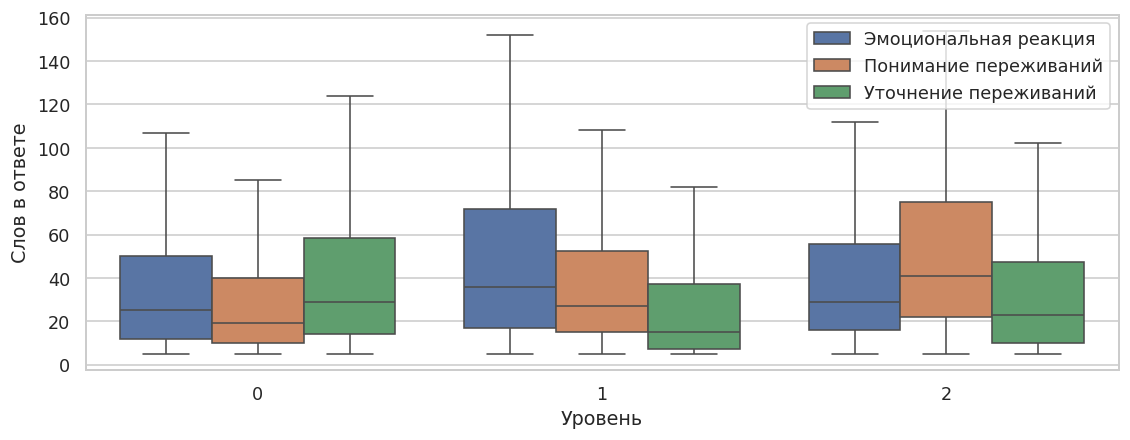

In [13]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="level", y="Слов в ответе", hue="признак", showfliers=False)
plt.xlabel("Уровень")
plt.legend(title=None)
plt.tight_layout()
plt.show()

## Итоги

Оценки трёх признаков распределены по-разному, поэтому при оценке модели полезно смотреть результаты по каждому уровню. Перед обучением нужно решить, как обрабатывать конфликтующие оценки и расхождения текста. При разбиении данных стоит группировать по `sp_id`, чтобы ответы на один исходный пост попадали в одну выборку.